# Slides 12 & 13 — Métriques de soutenance

Graphiques pour la présentation orale :

- **Slide 12** — Phase d'entraînement (LI-Small, jeu TEST 15 %)
- **Slide 13** — Phase de généralisation (LI-Medium, hold-out inconnu)

Les métriques sont chargées depuis les JSON du projet (`gnn_*_metrics.json`) si disponibles,
sinon les valeurs documentées dans `metrics_evaluation.ipynb` et `holdout_metrics_evaluation.ipynb`.

> Export PNG : `docs/figures/soutenance/`

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown


def find_project_root() -> Path:
    markers = ("src", "data", "scripts")
    candidates = [Path.cwd().resolve()]
    if (Path.cwd() / "notebooks").exists():
        candidates.insert(0, (Path.cwd() / "notebooks").resolve())
    for start in candidates:
        path = start
        for _ in range(8):
            if (path / "src" / "config.py").exists() and all((path / m).exists() for m in markers):
                return path
            if path.parent == path:
                break
            path = path.parent
    raise FileNotFoundError("Racine du projet introuvable.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.evaluation.metrics_viz import discover_metrics_files, metrics_to_dataframe
from src.evaluation.holdout_viz import holdout_metrics_dataframe

OUTPUT_DIR = PROJECT_ROOT / "docs" / "figures" / "soutenance"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    "GraphSAGE": "#3498db",
    "GAT": "#95a5a6",
    "HeteroGNN": "#e74c3c",
}
MODEL_KEYS = {"sage": "GraphSAGE", "gat": "GAT", "hetero": "HeteroGNN"}
METRICS = ["pr_auc", "recall", "precision", "f1"]
METRIC_LABELS = {
    "pr_auc": "PR-AUC",
    "recall": "Recall",
    "precision": "Précision",
    "f1": "F1-score",
}

print("Projet :", PROJECT_ROOT)
print("Export :", OUTPUT_DIR)

Projet : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project - Samir KHALDI
Export : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project - Samir KHALDI\docs\figures\soutenance


In [2]:
# Valeurs de repli (notebooks metrics_evaluation + holdout_metrics_evaluation)
FALLBACK_TRAIN = {
    "phase": "Entraînement",
    "dataset": "LI-Small — jeu TEST (15 %)",
    "n_samples": 30_000,
    "n_fraud": 534,
    "fraud_rate": 1.78,
    "models": {
        "GraphSAGE": {"pr_auc": 0.119, "recall": 0.839, "precision": 0.038, "f1": 0.073},
        "GAT": {"pr_auc": 0.047, "recall": 0.625, "precision": 0.030, "f1": 0.056},
        "HeteroGNN": {"pr_auc": 0.430, "recall": 0.749, "precision": 0.216, "f1": 0.335},
    },
}

FALLBACK_HOLDOUT = {
    "phase": "Généralisation",
    "dataset": "LI-Medium — hold-out inconnu",
    "n_samples": 200_000,
    "n_fraud": 16_041,
    "fraud_rate": 8.02,
    "models": {
        "GraphSAGE": {"pr_auc": 0.229, "recall": 0.781, "precision": 0.133, "f1": 0.228},
        "GAT": {"pr_auc": 0.150, "recall": 0.643, "precision": 0.114, "f1": 0.194},
        "HeteroGNN": {"pr_auc": 0.595, "recall": 0.699, "precision": 0.544, "f1": 0.612},
    },
}


def _df_to_phase(df: pd.DataFrame, split: str, phase: str, dataset: str) -> dict:
    sub = df[df["split"] == split]
    if sub.empty:
        return {}
    row0 = sub.iloc[0]
    models = {}
    for _, row in sub.iterrows():
        label = MODEL_KEYS.get(row["model"], row["model"])
        models[label] = {
            "pr_auc": float(row["pr_auc"]),
            "recall": float(row["recall"]),
            "precision": float(row["precision"]),
            "f1": float(row["f1"]),
        }
    n_samples = int(sub["n_samples"].iloc[0])
    n_fraud = int(sub["n_fraud"].iloc[0])
    return {
        "phase": phase,
        "dataset": dataset,
        "n_samples": n_samples,
        "n_fraud": n_fraud,
        "fraud_rate": round(100 * n_fraud / n_samples, 2),
        "models": models,
    }


def load_train_phase() -> dict:
    files = discover_metrics_files(config.TRAIN_RESULTS_DIR)
    if files:
        df = metrics_to_dataframe(files)
        phase = _df_to_phase(df, "test", "Entraînement", "LI-Small — jeu TEST (15 %)")
        if phase:
            return phase
    return FALLBACK_TRAIN.copy()


def load_holdout_phase() -> dict:
    config.set_data_profile("unknown")
    try:
        df = holdout_metrics_dataframe()
        phase = _df_to_phase(df, "holdout", "Généralisation", "LI-Medium — hold-out inconnu")
        if phase:
            return phase
    except FileNotFoundError:
        pass
    return FALLBACK_HOLDOUT.copy()


TRAIN_PHASE = load_train_phase()
HOLDOUT_PHASE = load_holdout_phase()

for name, phase in [("Entraînement", TRAIN_PHASE), ("Généralisation", HOLDOUT_PHASE)]:
    rows = [{"modèle": m, **v} for m, v in phase["models"].items()]
    display(Markdown(f"### {name} — {phase['dataset']}"))
    display(pd.DataFrame(rows).set_index("modèle").round(3))

### Entraînement — LI-Small — jeu TEST (15 %)

,pr_auc,recall,precision,f1
modèle,,,,
GAT,0.047,0.625,0.030,0.056
HeteroGNN,0.430,0.749,0.216,0.335
GraphSAGE,0.119,0.839,0.038,0.073


### Généralisation — LI-Medium — hold-out inconnu

,pr_auc,recall,precision,f1
modèle,,,,
HeteroGNN,0.595,0.699,0.544,0.612
GraphSAGE,0.229,0.781,0.133,0.228
GAT,0.150,0.643,0.114,0.194


In [3]:
def set_plot_style() -> None:
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "#fafafa",
        "axes.edgecolor": "#cccccc",
        "axes.labelcolor": "#2c3e50",
        "text.color": "#2c3e50",
        "font.family": "sans-serif",
        "font.size": 11,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
    })


def _annotate_bars(ax, bars, values) -> None:
    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"{val * 100:.0f} %",
            ha="center", va="bottom", fontsize=10,
            fontweight="bold" if val == max(values) else "normal",
        )


def plot_phase_slide(phase_data: dict, highlight_metric: str, save_name: str | None = None):
    """Gabarit commun — Slide 12 (précision) / Slide 13 (PR-AUC) + F1-score."""
    set_plot_style()
    models = list(phase_data["models"].keys())
    x = np.arange(len(METRICS))
    width = 0.25

    fig, ax = plt.subplots(figsize=(13, 6.5))

    for i, model in enumerate(models):
        vals = [phase_data["models"][model][m] for m in METRICS]
        bars = ax.bar(
            x + (i - 1) * width, vals, width,
            label=model, color=COLORS[model],
            edgecolor="white", linewidth=0.8, zorder=3,
        )
        _annotate_bars(ax, bars, vals)

    ax.set_xticks(x)
    ax.set_xticklabels([METRIC_LABELS[m] for m in METRICS], fontsize=12)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Score (0 – 1)", fontsize=11)
    ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)
    ax.set_axisbelow(True)

    phase = phase_data["phase"]
    title = (
        f"Phase d'{phase.lower()}"
        if phase == "Entraînement"
        else f"Phase de {phase.lower()}"
    )
    ax.set_title(f"{title} — {phase_data['dataset']}", pad=14)
    ax.text(
        0.5, 1.02,
        f"{phase_data['n_samples']:,} transactions · "
        f"{phase_data['n_fraud']:,} fraudes ({phase_data['fraud_rate']:.2f} %)",
        transform=ax.transAxes, ha="center", fontsize=10, color="#555",
    )

    h = phase_data["models"]["HeteroGNN"]
    if phase == "Entraînement":
        sage_p = phase_data["models"]["GraphSAGE"]["precision"]
        msg = (
            f"Modèles standards : précision ≈ {sage_p * 100:.0f} % → fausses alertes massives\n"
            f"HeteroGNN : PR-AUC {h['pr_auc']:.2f} · F1 {h['f1']:.2f} "
            f"(×{h['pr_auc'] / sage_p:.0f} meilleur classement)"
        )
    else:
        msg = (
            f"HeteroGNN : PR-AUC {h['pr_auc']:.2f} · Recall {h['recall'] * 100:.0f} % · "
            f"Précision {h['precision'] * 100:.0f} % · F1 {h['f1']:.2f}\n"
            f"→ plus d'une alerte sur deux est une vraie fraude"
        )

    fig.text(
        0.5, 0.01, msg, ha="center", va="bottom", fontsize=10.5, color="#2c3e50",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#ecf0f1", edgecolor="#bdc3c7"),
    )

    hi = METRICS.index(highlight_metric)
    ax.add_patch(mpatches.FancyBboxPatch(
        (hi - 0.42, 0), 0.84, 1.02,
        boxstyle="round,pad=0.02,rounding_size=0.02",
        linewidth=2, edgecolor="#e74c3c", facecolor="none", linestyle="--",
        transform=ax.get_xaxis_transform(), zorder=4,
    ))

    ax.legend(loc="upper right", framealpha=0.95, title="Modèle")
    fig.tight_layout(rect=[0, 0.06, 1, 0.96])

    if save_name:
        path = OUTPUT_DIR / save_name
        fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
        print(f"Exporté : {path}")

    plt.show()
    return fig

## Slide 12 — Résultat sur la phase d'entraînement

> *« Les modèles standards inondent les résultats de fausses alertes (moins de 4 % de précision).
> Notre HeteroGNN apporte un meilleur classement (PR-AUC) dès la phase d'entraînement. »*

Exporté : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project - Samir KHALDI\docs\figures\soutenance\slide12_phase_entrainement.png


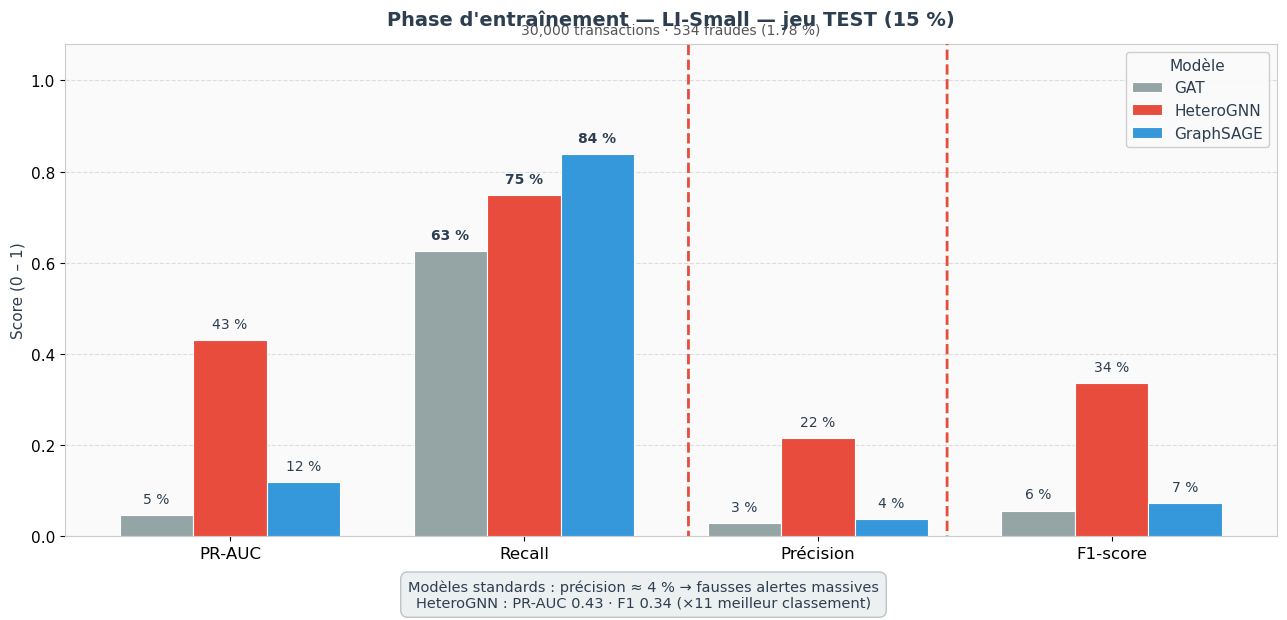

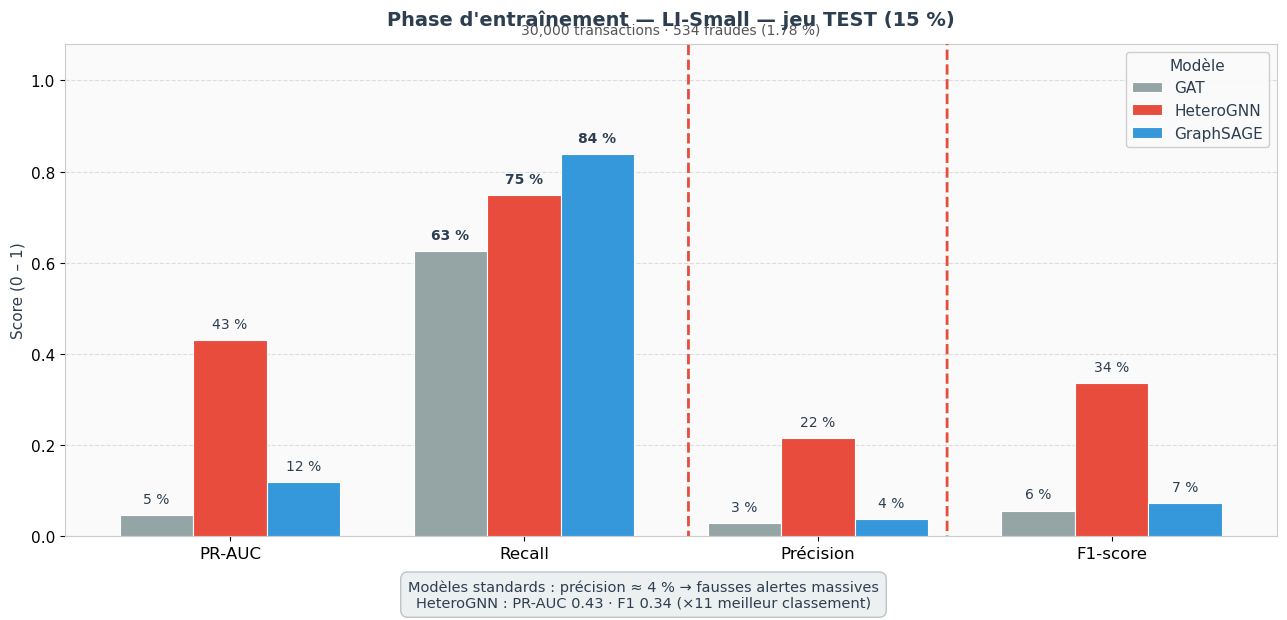

In [4]:
plot_phase_slide(
    TRAIN_PHASE,
    highlight_metric="precision",
    save_name="slide12_phase_entrainement.png",
)

## Slide 13 — Résultat sur la phase de généralisation

> *« Sur un jeu de données inconnu (LI-Medium), le HeteroGNN atteint PR-AUC 0,60,
> intercepte 70 % des fraudes, avec 54 % de précision et F1 0,61 — plus d'une alerte sur deux est réelle. »*

Exporté : C:\Users\MASTER DATA&IA\Desktop\YNOV\Projet - Connect AI\Project - Samir KHALDI\docs\figures\soutenance\slide13_phase_generalisation.png


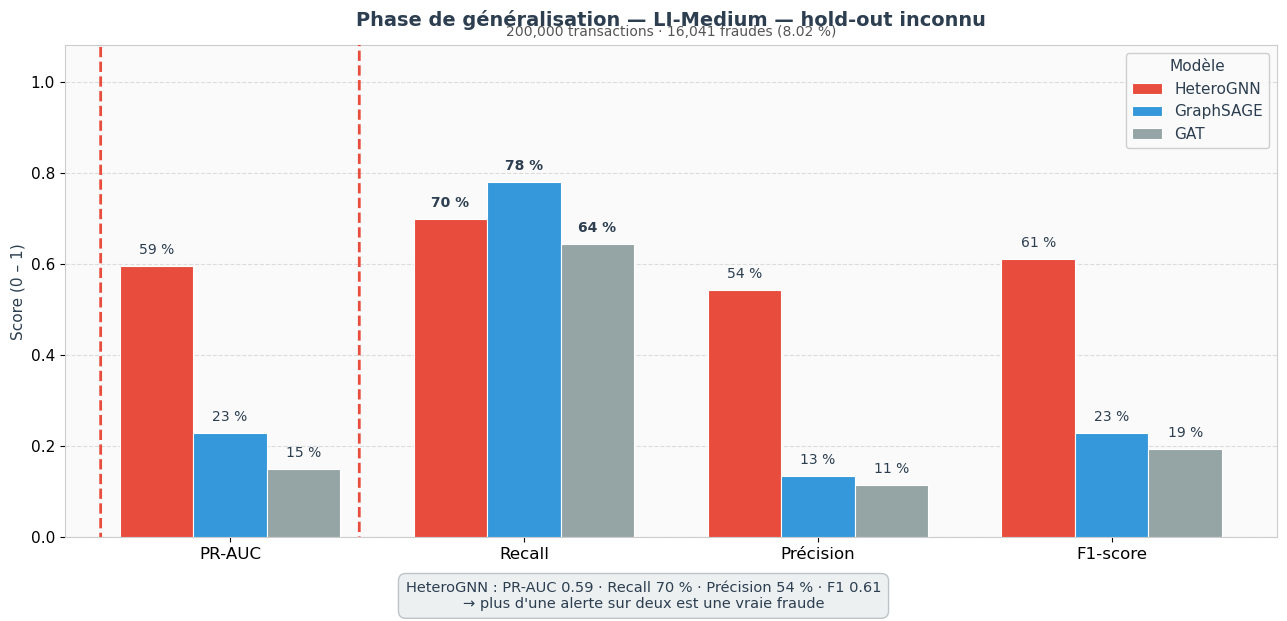

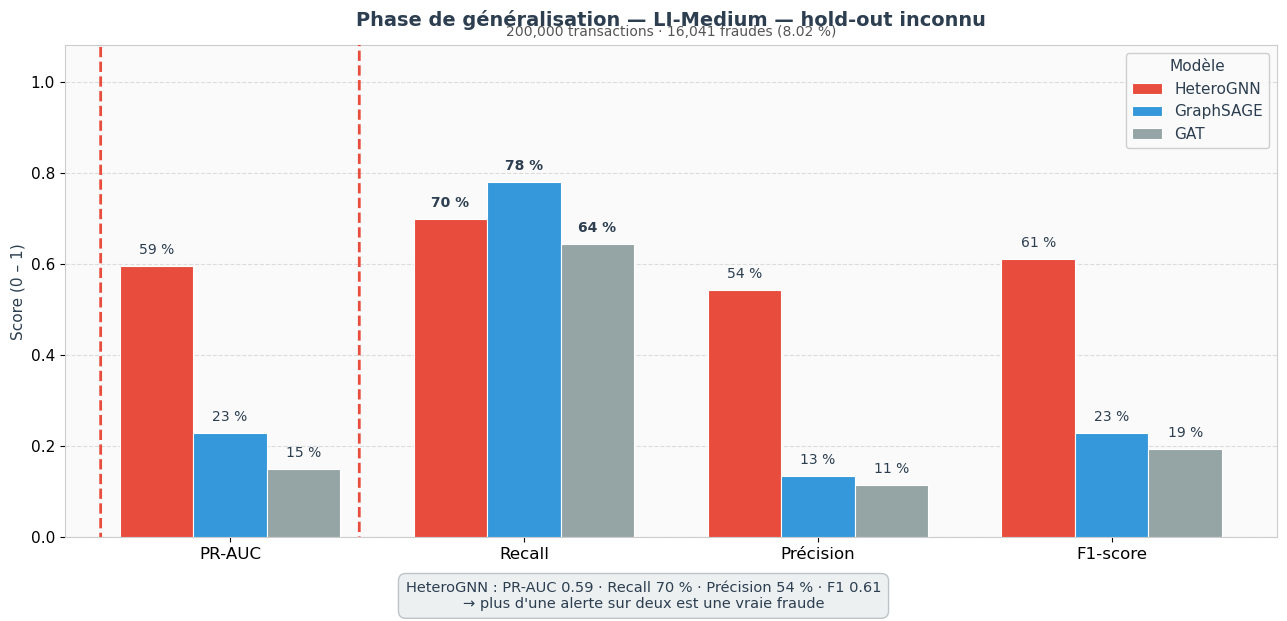

In [5]:
plot_phase_slide(
    HOLDOUT_PHASE,
    highlight_metric="pr_auc",
    save_name="slide13_phase_generalisation.png",
)

## Aperçu des fichiers exportés

**slide12_13_precision_comparative.png**

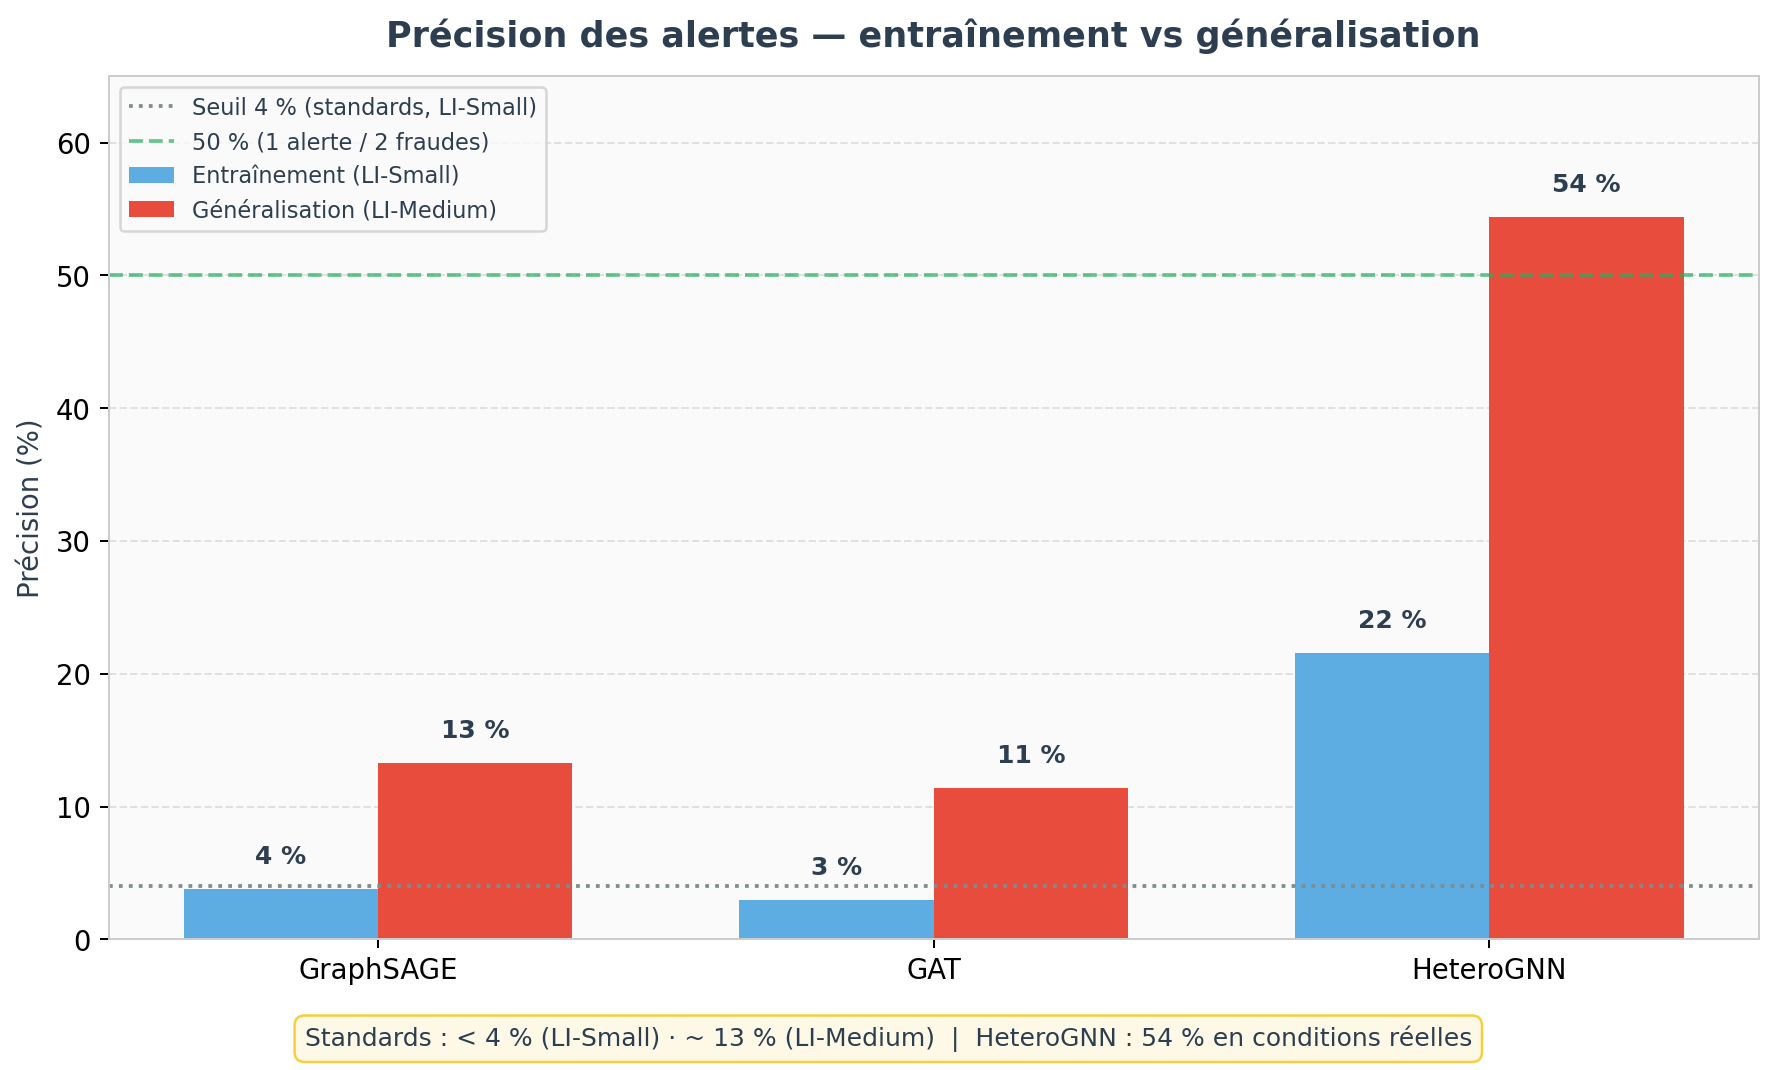

**slide12_phase_entrainement.png**

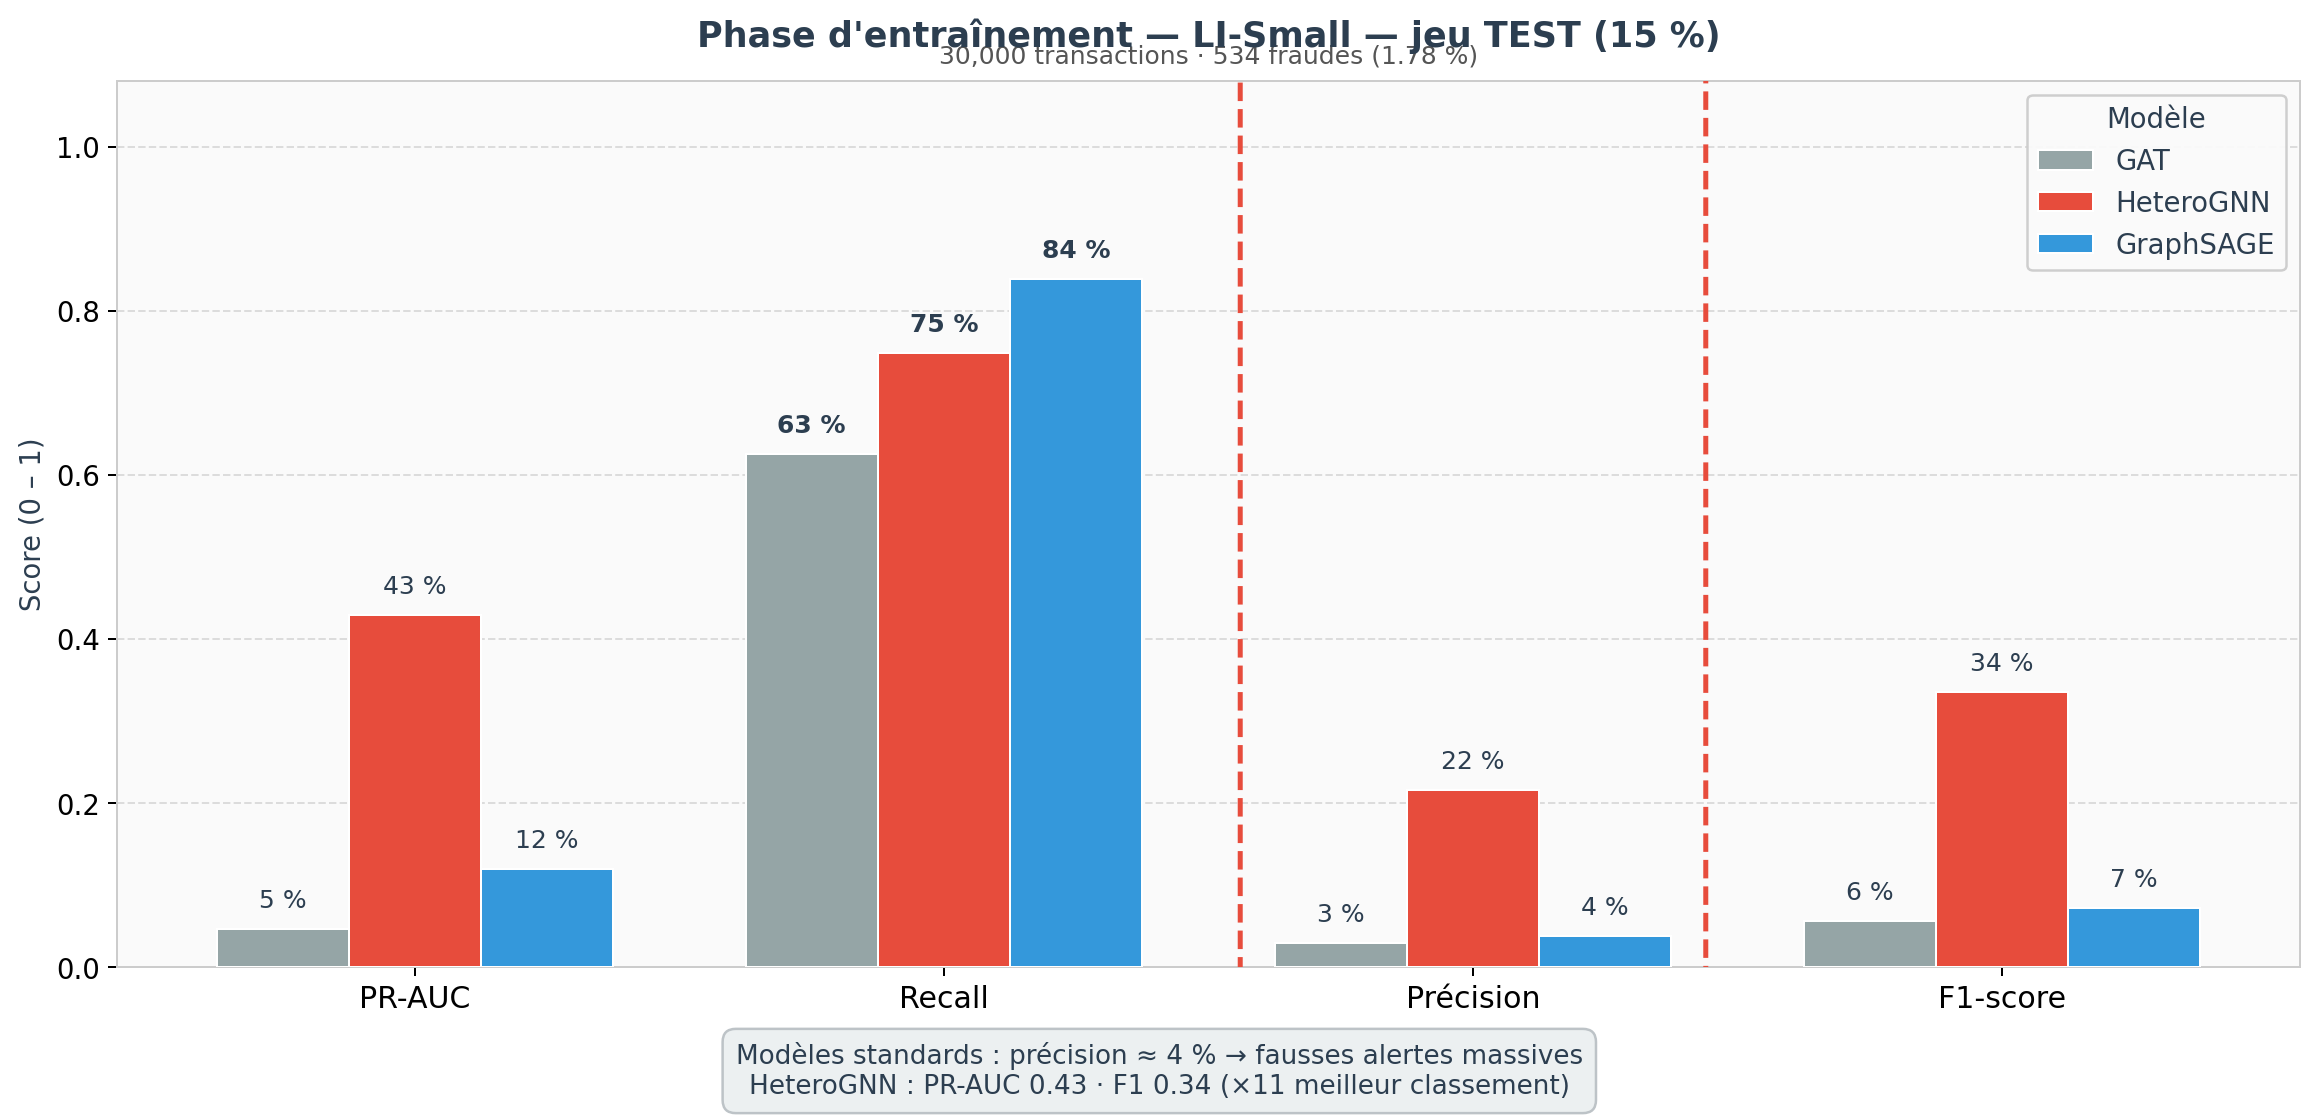

**slide13_phase_generalisation.png**

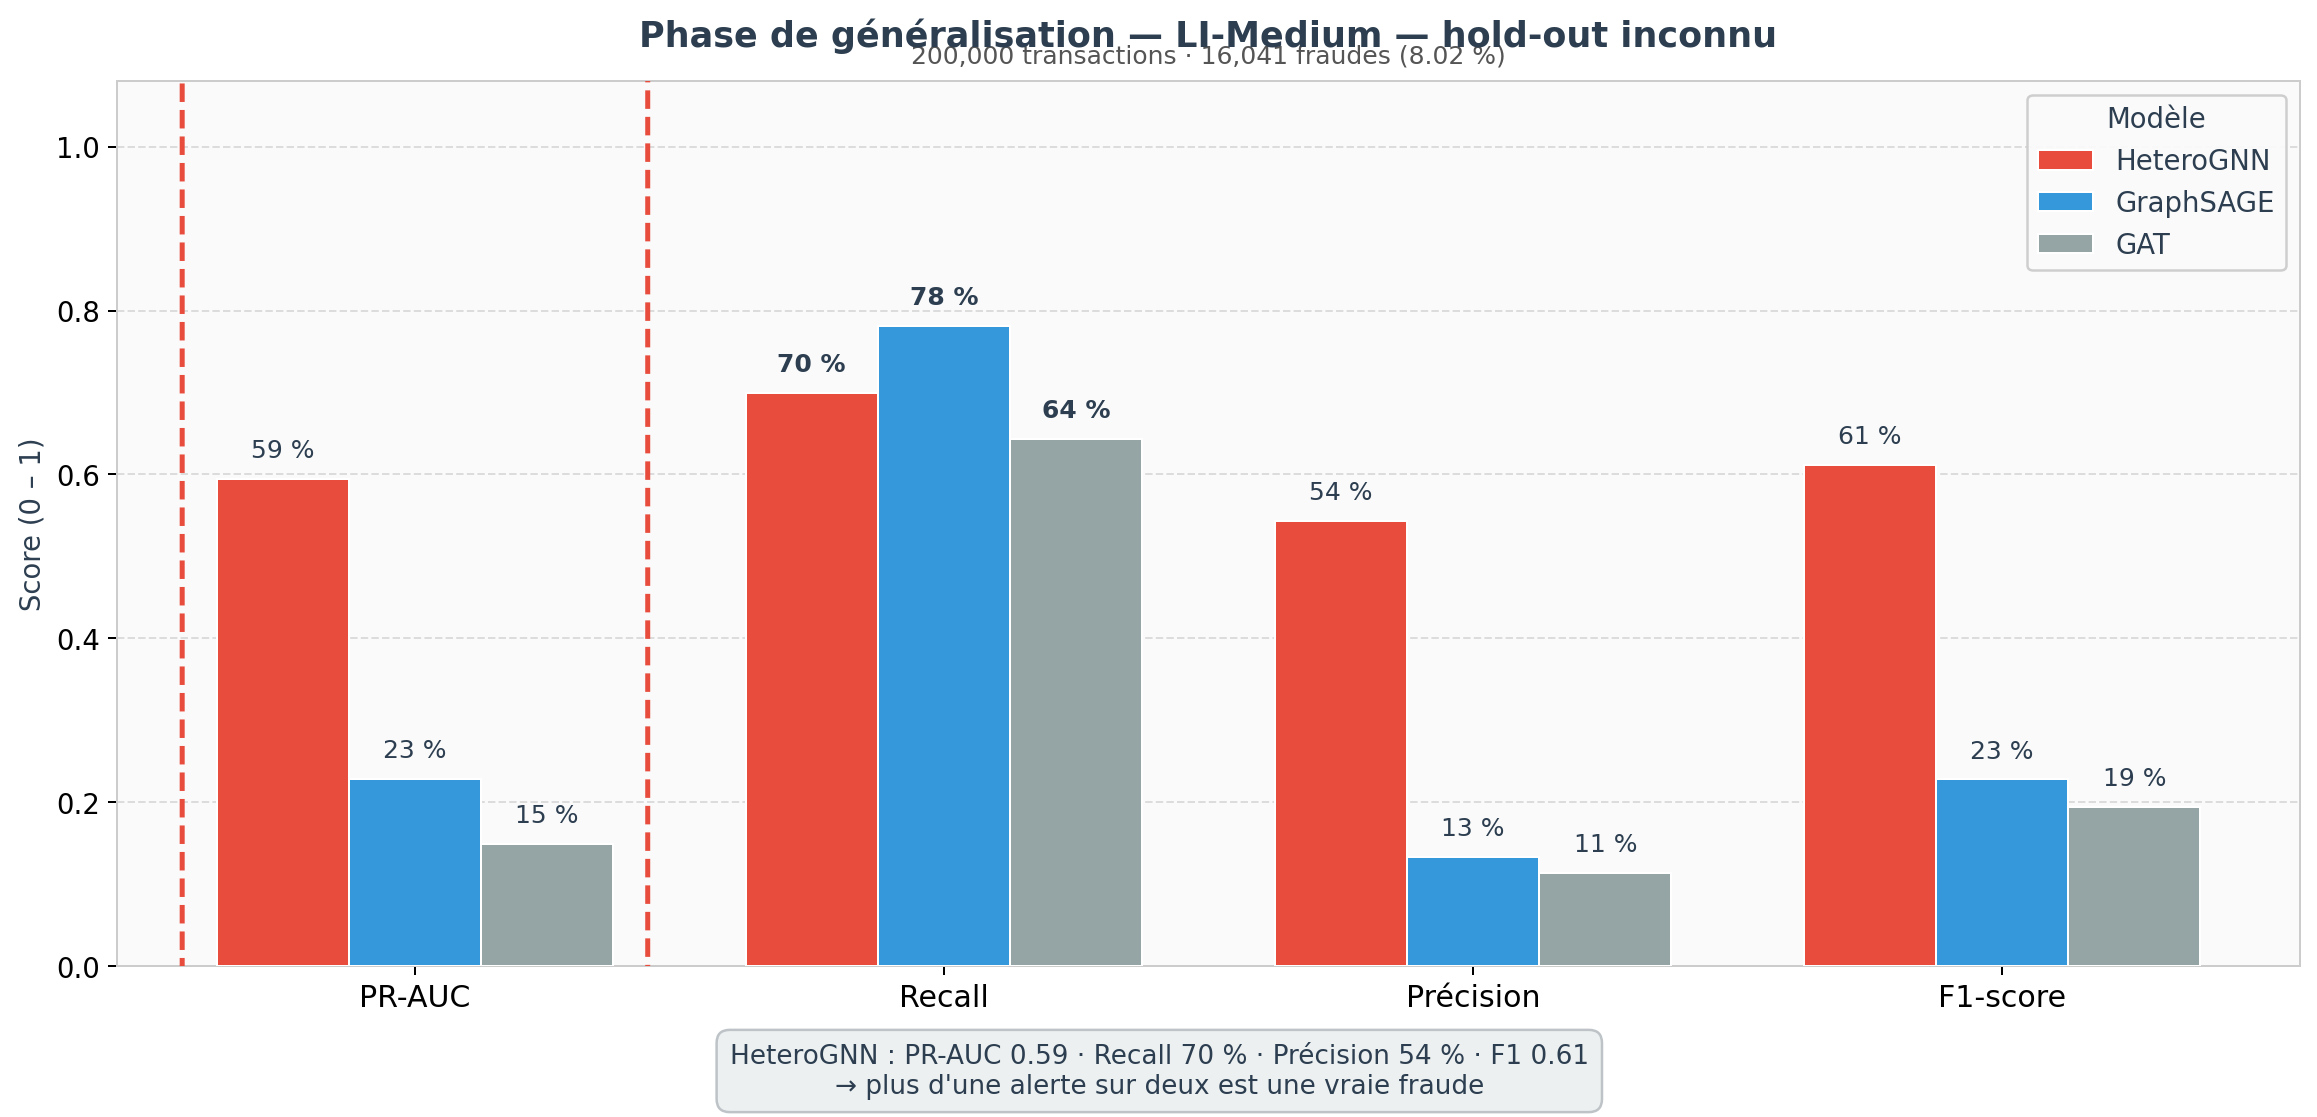

In [6]:
for png in sorted(OUTPUT_DIR.glob("slide1*.png")):
    display(Markdown(f"**{png.name}**"))
    display(Image(filename=str(png)))